# My pipeline: accuracy and model–recording L2 vs how the emitter moves

Pipeline: **numerical, sink at tail tip** (BEM conductivities: interior 100 × water, skin 0.05 × water over 0.005 cm; model
sign fixed), from `results/eod_ground_truth{,_3fish}/conductivities/eod_assignments.csv`:
- **correct** = the EOD is assigned to the emitter (2 fish: fish 1; 3 fish: fish 0);
- **L2** = that pipeline's distance of the emitter: L2 between its 10 model pair voltages (sign fixed) and the recorded ones,
  both scaled to max |v| = 1 (column `distance fish <emitter> | ...`).

EODs: the **better list of good frames** (`good_frames_better_list.csv`), all of them (red) and those where the nearest other
fish is at least `FAR_CM` away (blue; `gap_cm`, mask edge to edge).

Motion of the emitter around each EOD frame k, from its mask midline (`midline_methods.fish_midline_with_head`, 101 points,
tail → head) in the video frames k − 1 and k + 1 (2 / fps apart). If the head rule picked opposite ends in the two frames, the
k + 1 midline is reversed first.
- **velocity**: displacement of the midline centroid (cm/s);
- **head angular speed**: change of direction of the head third of the midline (°/s);
- **body angular speed**: change of direction of the whole-body axis, tail tip → head tip (°/s);
- **tail angular speed**: change of the angle of the tail third relative to the head third (°/s), so a rotation of the
  whole fish does not count.

The motion code is in `eod_motion.py`.

Accuracy error bars: 95% Wilson intervals. L2: line = median, band = interquartile range. Bins with fewer than 20 EODs are
not plotted.

In [1]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eod_motion as em                          # mask-midline motion (imports mask_metrics, which sets the Agg backend...)
%matplotlib inline

PIPE = 'BEM σ (interior 100, skin 0.05, 0.005 cm), sink at tail tip'
RECORDINGS = {
    '2 fish': dict(out='results/eod_ground_truth', emitter=1,
                   track='data/2_fish_silent/elephantnose_20240213T143321_tracking_final.pkl'),
    '3 fish': dict(out='results/eod_ground_truth_3fish', emitter=0,
                   track='data/3_fish_silent/elephantnose_20241015T141225_tracking_final.pkl'),
}
FAR_CM = 10
MEASURES = {   # column: (x label, bins)
    'velocity_cm_s': ('velocity (cm/s)', np.arange(0, 41, 2.5)),
    'head_angular_deg_s': ('head angular speed (°/s)', np.arange(0, 801, 50)),
    'body_angular_deg_s': ('body angular speed (°/s)', np.arange(0, 401, 25)),
    'tail_angular_deg_s': ('tail angular speed, relative to the body (°/s)', np.arange(0, 1001, 50)),
}
assert tuple(MEASURES) == em.MEASURES
GROUPS = {'good frames': '#C8361E', f'good frames, other fish ≥ {FAR_CM} cm': '#1F5FBF'}

## Motion of the emitter at each good-frame EOD

In [2]:
data = {}
for rec, cfg in RECORDINGS.items():
    A = pd.read_csv(f"{cfg['out']}/conductivities/eod_assignments.csv", index_col='row')
    better = A.Frame.isin(pd.read_csv(f"{cfg['out']}/good_frames_better_list.csv").frame)
    G = A[better].copy()
    with open(cfg['track'], 'rb') as f:
        trk = pickle.load(f)
    frames, fps = trk['frames'], trk['fps']
    mo = {k: em.motion(frames, int(k), cfg['emitter'], fps) for k in G.Frame.unique() if 0 < k < len(frames) - 1}
    G[list(MEASURES)] = np.array([mo.get(k, (np.nan,) * len(MEASURES)) for k in G.Frame])
    G['correct'] = G[f'fish | {PIPE}'] == cfg['emitter']
    G['l2'] = G[f"distance fish {cfg['emitter']} | {PIPE}"]
    G['far'] = G.gap_cm >= FAR_CM
    data[rec] = G
    G[['Frame', 'gap_cm', 'far', 'correct', 'l2', *MEASURES]].round(3).to_csv(
        f"{cfg['out']}/conductivities/motion_per_eod_better_list.csv")
    print(f"{rec}: {len(G)} EODs on the better list, {G[list(MEASURES)].notna().all(axis=1).sum()} with motion, "
          f"{G.far.sum()} with the other fish ≥ {FAR_CM} cm; overall {G.correct.mean() * 100:.1f}% correct, median L2 {G.l2.median():.2f}")
    display(G[list(MEASURES)].describe(percentiles=[0.5, 0.9, 0.99]).round(0).T)

2 fish: 3501 EODs on the better list, 3501 with motion, 2822 with the other fish ≥ 10 cm; overall 96.7% correct, median L2 0.37


,count,mean,std,min,50%,90%,99%,max
velocity_cm_s,3501.0,9.0,9.0,0.0,7.0,24.0,38.0,49.0
head_angular_deg_s,3501.0,60.0,77.0,0.0,33.0,150.0,350.0,1028.0
body_angular_deg_s,3501.0,51.0,56.0,0.0,31.0,129.0,253.0,471.0
tail_angular_deg_s,3501.0,173.0,195.0,0.0,106.0,437.0,864.0,1410.0


3 fish: 6751 EODs on the better list, 6751 with motion, 4022 with the other fish ≥ 10 cm; overall 94.5% correct, median L2 0.56


,count,mean,std,min,50%,90%,99%,max
velocity_cm_s,6751.0,9.0,10.0,0.0,5.0,25.0,45.0,53.0
head_angular_deg_s,6751.0,93.0,149.0,0.0,40.0,249.0,725.0,1925.0
body_angular_deg_s,6751.0,114.0,117.0,0.0,80.0,250.0,554.0,1148.0
tail_angular_deg_s,6751.0,402.0,360.0,0.0,307.0,851.0,1688.0,2920.0


## Accuracy and L2 vs velocity, head and body angular speed

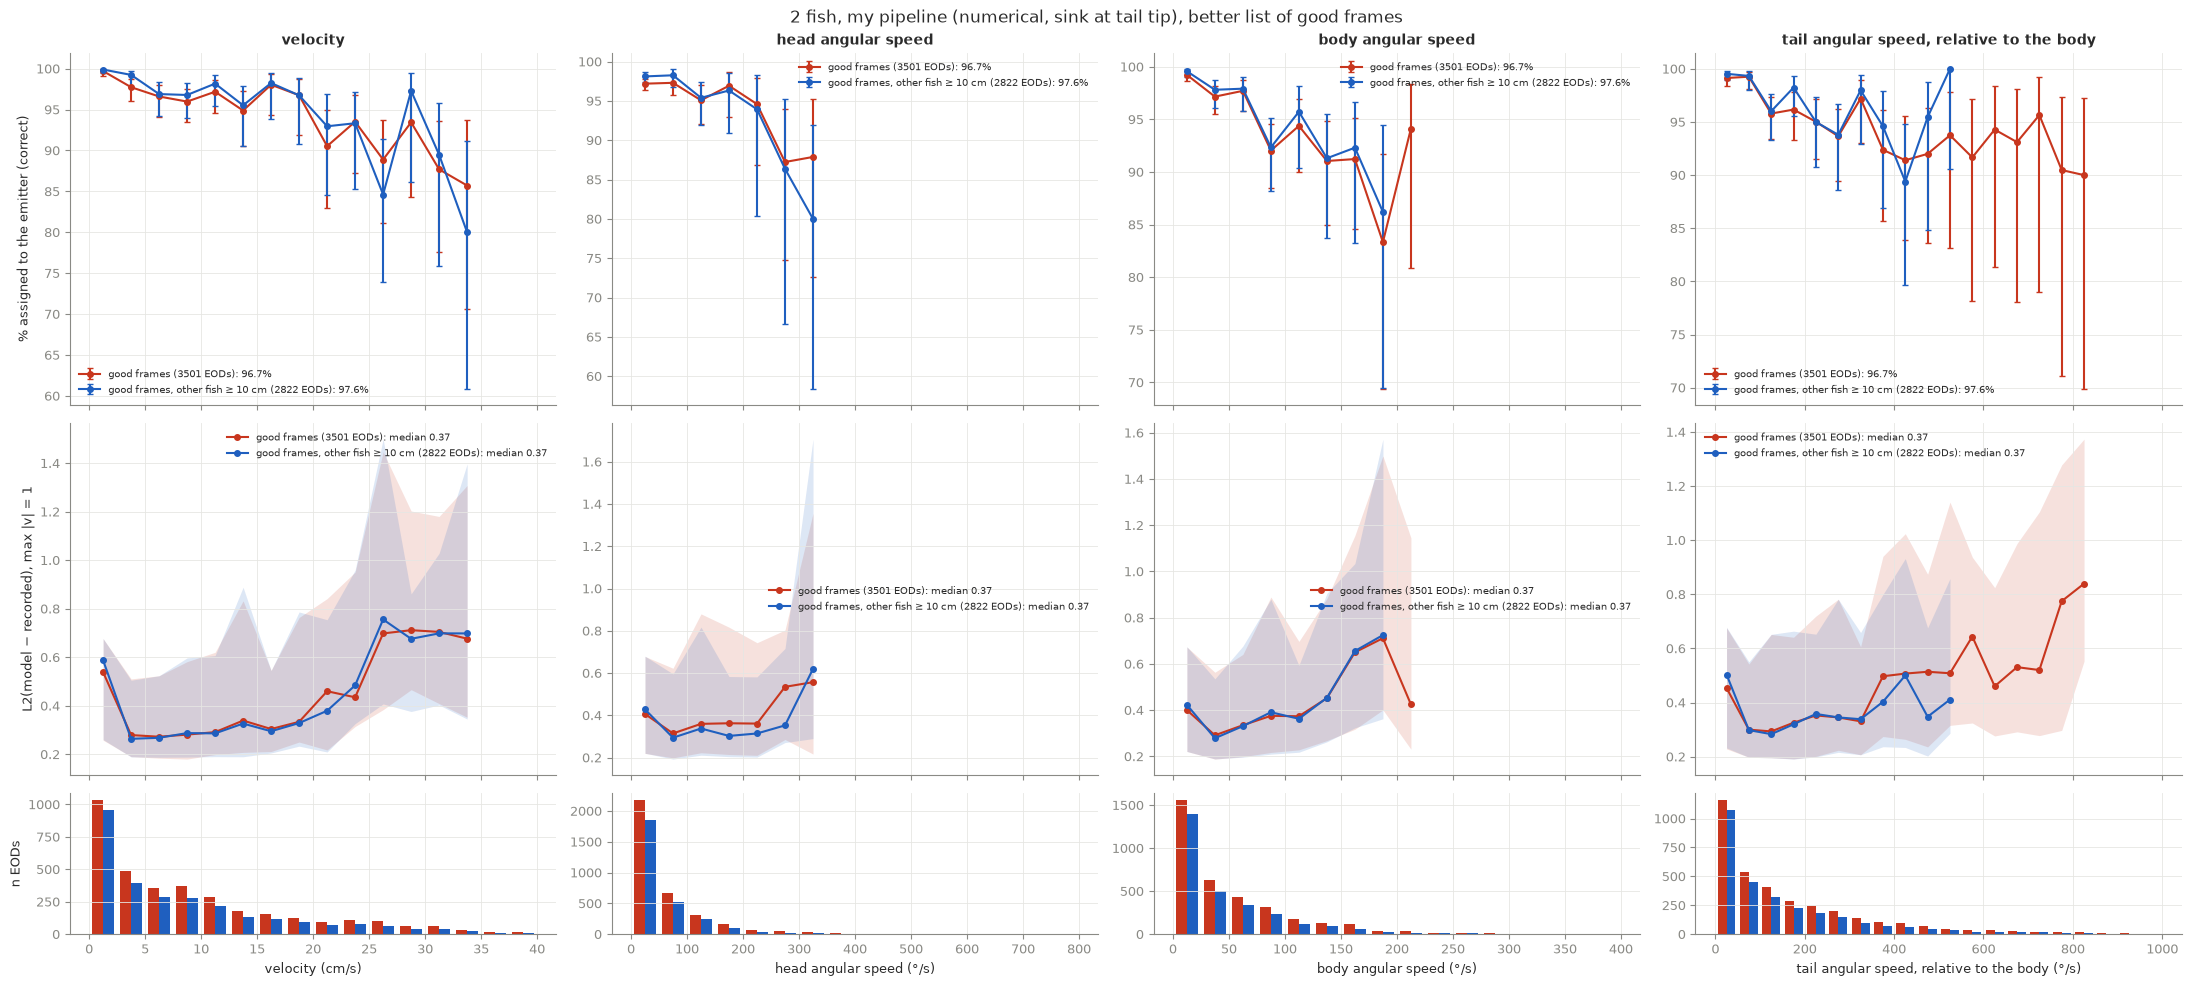

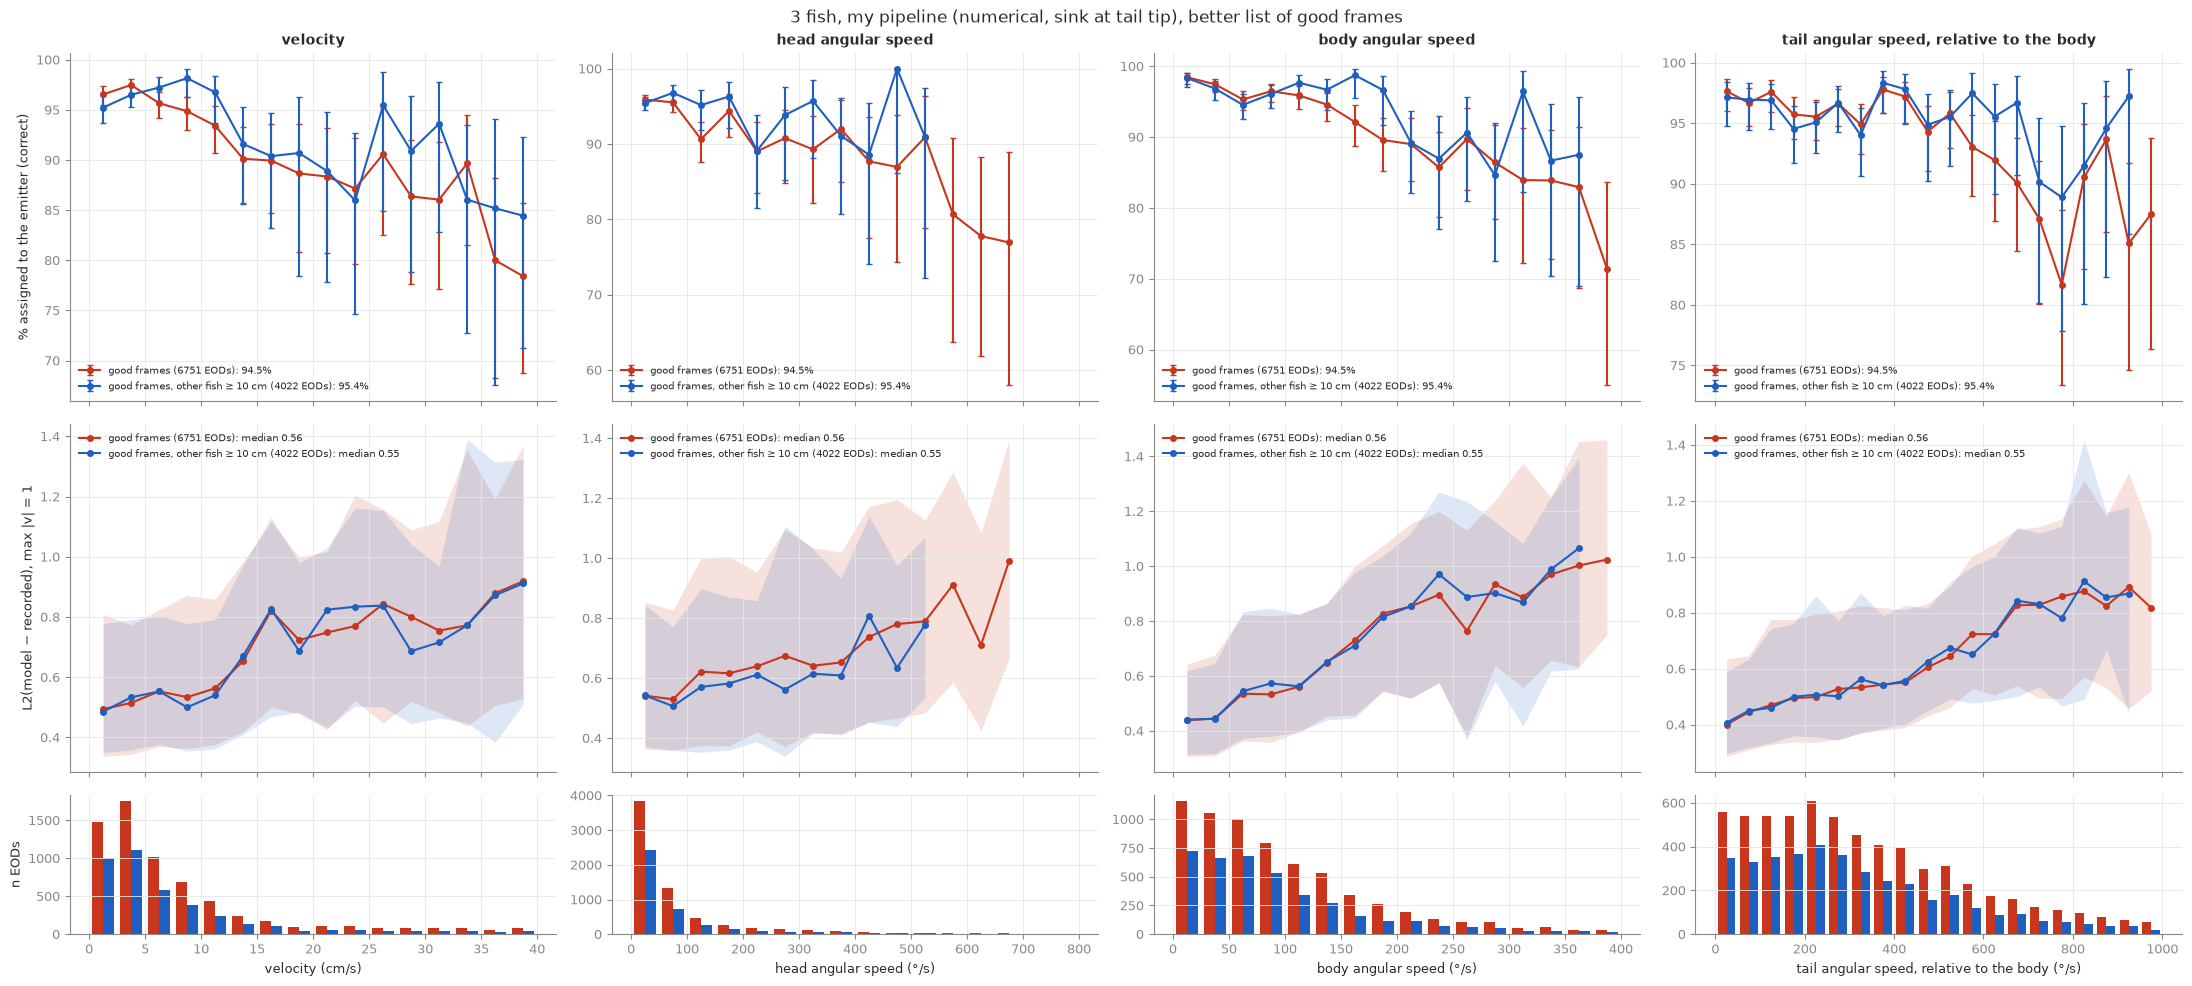

In [3]:
def wilson(k, n, z=1.96):
    '''95% Wilson interval of k successes in n trials, in %.'''
    p = k / n; c = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n); hw = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return 100 * (c - hw), 100 * (c + hw)

for rec, G in data.items():
    fig, axs = plt.subplots(3, len(MEASURES), figsize=(22, 10), sharex='col', height_ratios=[3, 3, 1.2])
    rows = []
    for j, (col, (xlabel, bins)) in enumerate(MEASURES.items()):
        width = np.diff(bins).min() * 0.4
        for g, (name, colour) in enumerate(GROUPS.items()):
            S = G[G[col].notna() & (G.far if g else True)]
            gr = S.groupby(pd.cut(S[col], bins), observed=False)
            t = pd.DataFrame({'n': gr.size(), 'n_correct': gr.correct.sum(), 'l2_median': gr.l2.median(),
                              'l2_q25': gr.l2.quantile(0.25), 'l2_q75': gr.l2.quantile(0.75)})
            t['pct_correct'] = 100 * t.n_correct / t.n
            t['lo'], t['hi'] = wilson(t.n_correct, t.n)
            x = np.array([i.mid for i in t.index]); ok = (t.n >= 20).to_numpy()
            lbl = f'{name} ({len(S)} EODs)'
            axs[0, j].errorbar(x[ok], t.pct_correct[ok], yerr=[(t.pct_correct - t.lo)[ok], (t.hi - t.pct_correct)[ok]],
                               color=colour, marker='o', ms=4, capsize=2, label=f'{lbl}: {S.correct.mean() * 100:.1f}%')
            axs[1, j].plot(x[ok], t.l2_median[ok], color=colour, marker='o', ms=4, label=f'{lbl}: median {S.l2.median():.2f}')
            axs[1, j].fill_between(x[ok], t.l2_q25[ok], t.l2_q75[ok], color=colour, alpha=0.15, lw=0)
            axs[2, j].bar(x + (g - 0.5) * width, t.n, width, color=colour)
            rows.append(t.drop(columns=['lo', 'hi']).assign(measure=col, EODs=name))
        axs[0, j].set(title=xlabel.split(' (')[0])
        axs[2, j].set(xlabel=xlabel)
    axs[0, 0].set_ylabel('% assigned to the emitter (correct)')
    axs[1, 0].set_ylabel('L2(model − recorded), max |v| = 1')
    axs[2, 0].set_ylabel('n EODs')
    for a in axs[:2].flat:
        a.legend(fontsize=7.5, frameon=False)
    for a in axs.flat:
        a.spines[['top', 'right']].set_visible(False)
    fig.suptitle(f'{rec}, my pipeline (numerical, sink at tail tip), better list of good frames', fontsize=12)
    fig.tight_layout()
    out = RECORDINGS[rec]['out']
    fig.savefig(f'{out}/conductivities/figures/accuracy_l2_vs_motion_my_pipeline.png', dpi=130)
    plt.show()
    pd.concat(rows).rename_axis('bin').round(3).to_csv(f'{out}/conductivities/accuracy_l2_vs_motion_my_pipeline.csv')

## Summary: slow / medium / fast

In [4]:
EDGES = {'velocity_cm_s': [0, 5, 15, np.inf], 'head_angular_deg_s': [0, 100, 300, np.inf], 'body_angular_deg_s': [0, 50, 150, np.inf],
         'tail_angular_deg_s': [0, 100, 250, np.inf]}
rows = []
for rec, G in data.items():
    for col, edges in EDGES.items():
        for name, S in [('good frames', G), (f'other fish ≥ {FAR_CM} cm', G[G.far])]:
            S = S[S[col].notna()]
            gr = S.groupby(pd.cut(S[col], edges, right=False), observed=True)
            rows.append(pd.DataFrame({'recording': rec, 'measure': col, 'EODs': name, 'n': gr.size(),
                                      '% correct': gr.correct.mean() * 100, 'median L2': gr.l2.median()}))
summary = pd.concat(rows).rename_axis('bin').reset_index().set_index(['recording', 'measure', 'EODs', 'bin']).round(2)
summary

n  \
recording measure            EODs               bin                    
2 fish    velocity_cm_s      good frames        [0.0, 5.0)      1519   
                                                [5.0, 15.0)     1186   
                                                [15.0, inf)      796   
                             other fish ≥ 10 cm [0.0, 5.0)      1354   
                                                [5.0, 15.0)      923   
                                                [15.0, inf)      545   
          head_angular_deg_s good frames        [0.0, 100.0)    2844   
                                                [100.0, 300.0)   589   
                                                [300.0, inf)      68   
                             other fish ≥ 10 cm [0.0, 100.0)    2379   
                                                [100.0, 300.0)   403   
                                                [300.0, inf)      40   
          body_angular_deg_s good frames        [0.0, 50.0)     2192   
                                                [50.0, 150.0)   1063   
                                                [150.0, inf)     246   
                             other fish ≥ 10 cm [0.0, 50.0)     1900   
                                                [50.0, 150.0)    780   
                                                [150.0, inf)     142   
          tail_angular_deg_s good frames        [0.0, 100.0)    1699   
                                                [100.0, 250.0)   932   
                                                [250.0, inf)     870   
                             other fish ≥ 10 cm [0.0, 100.0)    1519   
                                                [100.0, 250.0)   733   
                                                [250.0, inf)     570   
3 fish    velocity_cm_s      good frames        [0.0, 5.0)      3219   
                                                [5.0, 15.0)     2380   
                                                [15.0, inf)     1152   
                             other fish ≥ 10 cm [0.0, 5.0)      2120   
                                                [5.0, 15.0)     1335   
                                                [15.0, inf)      567   
          head_angular_deg_s good frames        [0.0, 100.0)    5167   
                                                [100.0, 300.0)  1052   
                                                [300.0, inf)     532   
                             other fish ≥ 10 cm [0.0, 100.0)    3145   
                                                [100.0, 300.0)   597   
                                                [300.0, inf)     280   
          body_angular_deg_s good frames        [0.0, 50.0)     2214   
                                                [50.0, 150.0)   2934   
                                                [150.0, inf)    1603   
                             other fish ≥ 10 cm [0.0, 50.0)     1387   
                                                [50.0, 150.0)   1825   
                                                [150.0, inf)     810   
          tail_angular_deg_s good frames        [0.0, 100.0)    1097   
                                                [100.0, 250.0)  1687   
                                                [250.0, inf)    3967   
                             other fish ≥ 10 cm [0.0, 100.0)     677   
                                                [100.0, 250.0)  1126   
                                                [250.0, inf)    2219   

                                                                % correct  \
recording measure            EODs               bin                         
2 fish    velocity_cm_s      good frames        [0.0, 5.0)          99.08   
                                                [5.0, 15.0)         96.29   
                                                [15.0, inf)         92.96   
                             other fish ≥ 10 cm [0.0, 5.0)          99.70   
    